# 04 - Predicción de retornos mensuales del Brent

## Pregunta de investigación

¿La incorporación de riesgo geopolítico y de variables del mercado petrolero mejora la predicción del **retorno porcentual del Brent del mes siguiente** respecto de usar únicamente su historia?

Este experimento es independiente del notebook `03_modelado_supervisado.ipynb`, que permanece sin cambios. Reutiliza sus escenarios, variables, modelos, partición cronológica y cinco folds de `TimeSeriesSplit`, pero reemplaza el objetivo de nivel por:

$$r_{t+1}=100\left(\frac{P_{t+1}}{P_t}-1\right).$$

Predecir retornos elimina gran parte de la persistencia del nivel. Por eso es un problema distinto y puede producir $R^2$ negativo sin que exista un error de implementación: significa que, en ese período, el modelo rinde peor que predecir la media observada en entrenamiento.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA_FILE = ROOT / "data" / "processed" / "brent_gpr_market_monthly.csv"

## 1. Datos, objetivo y escenarios

Cada fila representa una predicción realizada al cierre del mes `t`. El Brent de `t` y sus transformaciones causales están disponibles. Como los archivos no reconstruyen fechas históricas de publicación, GPR y las variables de mercado ingresan con un rezago conservador de un mes. No se crean rezagos adicionales sobre columnas que ya están retrasadas.

- **A - Brent:** nivel actual, rezagos, retornos, medias móviles y volatilidad.
- **B - Brent + GPR:** agrega tres transformaciones de GPR en `t−1`.
- **C - Brent + GPR + mercado:** agrega cinco variables de oferta/demanda en `t−1`.

El CSV conserva un retorno futuro en forma decimal. Aquí se recalcula desde los precios, se multiplica por 100 y se valida contra esa columna; el dataset original no se modifica.

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["month"]).sort_values("month").reset_index(drop=True)

assert df["month"].is_monotonic_increasing and df["month"].is_unique
assert df["month"].equals(pd.Series(pd.date_range(
    df["month"].min(), df["month"].max(), freq="MS"
), name="month"))
assert np.allclose(
    df["brent_price_next_month"].dropna(),
    df["brent_price"].shift(-1).dropna(),
)

stored_fractional_return = df["brent_return_next_month"].copy()
df["brent_return_next_month"] = 100 * (
    df["brent_price"].shift(-1) / df["brent_price"] - 1
)
assert np.allclose(
    df.loc[stored_fractional_return.notna(), "brent_return_next_month"],
    100 * stored_fractional_return.dropna(),
)

# Historia del Brent disponible al cierre de t: misma definición que el notebook 03.
for lag in [1, 2, 3, 6]:
    df[f"brent_lag_{lag}"] = df["brent_price"].shift(lag)
df["brent_return_1m"] = df["brent_price"].pct_change(fill_method=None)
df["brent_return_3m"] = df["brent_price"].pct_change(3, fill_method=None)
df["brent_ma_3"] = df["brent_price"].rolling(3).mean()
df["brent_ma_6"] = df["brent_price"].rolling(6).mean()
df["brent_volatility_6m"] = df["brent_return_1m"].rolling(6).std()

# Disponibilidad conservadora de información externa: valor de t-1.
df["gpr_lag_1"] = df["GPR"].shift(1)
df["gpr_change_lag_1"] = df["GPR"].diff().shift(1)
df["gpr_log_lag_1"] = np.log1p(df["GPR"]).shift(1)
for source in [
    "world_production", "world_consumption",
    "world_crude_production", "world_market_balance",
]:
    df[f"{source}_lag_1"] = df[source].shift(1)
df["world_market_balance_change_lag_1"] = df["world_market_balance"].diff().shift(1)

features_a = [
    "brent_price", "brent_lag_1", "brent_lag_2", "brent_lag_3", "brent_lag_6",
    "brent_return_1m", "brent_return_3m", "brent_ma_3", "brent_ma_6",
    "brent_volatility_6m",
]
features_b = features_a + ["gpr_lag_1", "gpr_change_lag_1", "gpr_log_lag_1"]
features_c = features_b + [
    "world_production_lag_1", "world_consumption_lag_1",
    "world_crude_production_lag_1", "world_market_balance_lag_1",
    "world_market_balance_change_lag_1",
]
scenarios = {
    "A - Brent": features_a,
    "B - Brent + GPR": features_b,
    "C - Brent + GPR + mercado": features_c,
}

required = features_c + ["brent_price_next_month", "brent_return_next_month"]
model_data = df.dropna(subset=required).copy().reset_index(drop=True)
model_data["target_month"] = model_data["month"] + pd.offsets.MonthBegin(1)

assert len(model_data) == 329
assert model_data["month"].min() == pd.Timestamp("1998-07-01")
assert model_data["month"].max() == pd.Timestamp("2025-11-01")
assert not any("next" in feature or "target" in feature for feature in features_c)
assert all(name.endswith("lag_1") for name in features_c if name.startswith(("gpr", "world")))

lag_check = model_data[["month", "gpr_lag_1", "world_market_balance_lag_1"]].merge(
    df[["month", "GPR", "world_market_balance"]].assign(
        month=lambda x: x["month"] + pd.offsets.MonthBegin(1)
    ),
    on="month",
    how="left",
)
assert np.allclose(lag_check["gpr_lag_1"], lag_check["GPR"])
assert np.allclose(lag_check["world_market_balance_lag_1"], lag_check["world_market_balance"])

display(pd.DataFrame({
    "escenario": scenarios.keys(),
    "cantidad_variables": [len(v) for v in scenarios.values()],
}))
print("Observaciones comunes:", len(model_data))
print("Meses de origen:", model_data["month"].min().date(), "a", model_data["month"].max().date())
print("Objetivo: retorno porcentual del mes siguiente")

Observaciones comunes: 329
Meses de origen: 1998-07-01 a 2025-11-01
Objetivo: retorno porcentual del mes siguiente


,escenario,cantidad_variables
0,A - Brent,10
1,B - Brent + GPR,13
2,C - Brent + GPR + mercado,18


## 2. Separación cronológica y folds

Se preserva literalmente el criterio del experimento original: 80 % inicial para entrenamiento/selección y 20 % final para test. Los modelos, hiperparámetros y escenarios se comparan solo dentro de cinco folds expansivos de `TimeSeriesSplit`; el test no participa en ninguna decisión.

In [3]:
split_index = int(len(model_data) * 0.80)
train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()
y_train = train["brent_return_next_month"]
y_test = test["brent_return_next_month"]

tscv = TimeSeriesSplit(n_splits=5)
fold_rows = []
for fold, (train_idx, valid_idx) in enumerate(tscv.split(train), start=1):
    fold_rows.append({
        "fold": fold,
        "train_inicio": train.iloc[train_idx]["month"].min(),
        "train_fin": train.iloc[train_idx]["month"].max(),
        "valid_inicio": train.iloc[valid_idx]["month"].min(),
        "valid_fin": train.iloc[valid_idx]["month"].max(),
        "n_train": len(train_idx),
        "n_valid": len(valid_idx),
    })
fold_table = pd.DataFrame(fold_rows)

assert len(train) == 263 and len(test) == 66
assert train["month"].max() < test["month"].min()
assert all(row.train_fin < row.valid_inicio for row in fold_table.itertuples())

print("Train (origen):", train["month"].min().date(), "a", train["month"].max().date(), f"({len(train)} meses)")
print("Test (origen): ", test["month"].min().date(), "a", test["month"].max().date(), f"({len(test)} meses)")
print("Test (objetivo):", test["target_month"].min().date(), "a", test["target_month"].max().date())
display(fold_table)

Train (origen): 1998-07-01 a 2020-05-01 (263 meses)
Test (origen):  2020-06-01 a 2025-11-01 (66 meses)
Test (objetivo): 2020-07-01 a 2025-12-01


,fold,train_inicio,train_fin,valid_inicio,valid_fin,n_train,n_valid
0,1,1998-07-01,2002-06-01,2002-07-01,2006-01-01,48,43
1,2,1998-07-01,2006-01-01,2006-02-01,2009-08-01,91,43
2,3,1998-07-01,2009-08-01,2009-09-01,2013-03-01,134,43
3,4,1998-07-01,2013-03-01,2013-04-01,2016-10-01,177,43
4,5,1998-07-01,2016-10-01,2016-11-01,2020-05-01,220,43


## 3. Modelos y baselines

Se reutilizan Ridge, Random Forest y Gradient Boosting con los mismos hiperparámetros base del notebook 03. El escalado de Ridge permanece dentro del `Pipeline`, de modo que se ajusta únicamente con el entrenamiento de cada fold. Los árboles no requieren escalado.

Los dos baselines se evalúan sobre las mismas observaciones:

1. **Retorno cero:** supone que el precio no cambia.
2. **Último retorno:** usa el retorno observado entre `t−1` y `t` como predicción de `t+1`.

MAE y RMSE están en puntos porcentuales; R² compara con la media del período evaluado y puede ser negativo.

In [4]:
regression_models = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Random Forest": Pipeline([("model", RandomForestRegressor(
        n_estimators=200, max_depth=6, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=1,
    ))]),
    "Gradient Boosting": Pipeline([("model", GradientBoostingRegressor(
        n_estimators=120, max_depth=2, learning_rate=0.04,
        random_state=RANDOM_STATE,
    ))]),
}

def metric_row(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

cv_rows = []
baseline_cv_rows = []
for fold, (train_idx, valid_idx) in enumerate(tscv.split(train), start=1):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    baseline_predictions = {
        "Baseline - retorno cero": np.zeros(len(valid_idx)),
        "Baseline - último retorno": 100 * train.iloc[valid_idx]["brent_return_1m"].to_numpy(),
    }
    for baseline_name, prediction in baseline_predictions.items():
        baseline_cv_rows.append({
            "fold": fold, "modelo": baseline_name,
            **metric_row(y_fold_valid, prediction),
        })

    for scenario, features in scenarios.items():
        for model_name, model in regression_models.items():
            fitted = clone(model).fit(train.iloc[train_idx][features], y_fold_train)
            valid_prediction = fitted.predict(train.iloc[valid_idx][features])
            train_prediction = fitted.predict(train.iloc[train_idx][features])
            cv_rows.append({
                "fold": fold,
                "escenario": scenario,
                "modelo": model_name,
                **metric_row(y_fold_valid, valid_prediction),
                "RMSE_train": root_mean_squared_error(y_fold_train, train_prediction),
            })

cv_folds = pd.DataFrame(cv_rows)
baseline_cv_folds = pd.DataFrame(baseline_cv_rows)
assert cv_folds.groupby(["escenario", "modelo"])["fold"].nunique().eq(5).all()
assert baseline_cv_folds.groupby("modelo")["fold"].nunique().eq(5).all()

cv_summary = (
    cv_folds.groupby(["escenario", "modelo"], as_index=False)
    .agg(
        MAE_CV=("MAE", "mean"), RMSE_CV=("RMSE", "mean"),
        RMSE_DE=("RMSE", "std"), R2_CV=("R2", "mean"),
        RMSE_train=("RMSE_train", "mean"),
    )
)
cv_summary["brecha_RMSE"] = cv_summary["RMSE_CV"] - cv_summary["RMSE_train"]
cv_summary = cv_summary.sort_values(["escenario", "RMSE_CV"]).reset_index(drop=True)

baseline_cv_summary = (
    baseline_cv_folds.groupby("modelo", as_index=False)
    .agg(MAE_CV=("MAE", "mean"), RMSE_CV=("RMSE", "mean"), RMSE_DE=("RMSE", "std"), R2_CV=("R2", "mean"))
    .sort_values("RMSE_CV")
)

print("Modelos (promedio de los mismos cinco folds):")
display(cv_summary.round(3))
print("Baselines (promedio de los mismos cinco folds):")
display(baseline_cv_summary.round(3))

Modelos (promedio de los mismos cinco folds):
Baselines (promedio de los mismos cinco folds):


,escenario,modelo,MAE_CV,RMSE_CV,RMSE_DE,R2_CV,RMSE_train,brecha_RMSE
0,A - Brent,Ridge,8.965,12.002,3.693,-0.594,8.934,3.067
1,A - Brent,Random Forest,9.197,12.277,2.081,-0.977,6.340,5.937
2,A - Brent,Gradient Boosting,9.674,12.817,2.180,-1.272,6.156,6.662
3,B - Brent + GPR,Random Forest,8.867,11.926,1.876,-0.890,6.056,5.870
4,B - Brent + GPR,Ridge,8.940,12.019,3.754,-0.586,8.639,3.381
5,B - Brent + GPR,Gradient Boosting,9.046,12.182,2.180,-0.941,5.891,6.291
6,C - Brent + GPR + mercado,Random Forest,8.846,11.805,1.983,-0.824,5.816,5.988
7,C - Brent + GPR + mercado,Gradient Boosting,8.956,11.885,2.340,-0.786,5.634,6.251
8,C - Brent + GPR + mercado,Ridge,11.501,14.879,4.580,-1.625,8.386,6.493


,modelo,MAE_CV,RMSE_CV,RMSE_DE,R2_CV
0,Baseline - retorno cero,7.485,10.119,3.702,-0.031
1,Baseline - último retorno,8.732,12.379,4.313,-0.597


## 4. Selección previa al test y evaluación final

Para cada escenario se congela la configuración con menor RMSE medio de validación. La comparación A/B/C usa el mismo target, las mismas filas y los mismos folds. Luego cada configuración se reajusta con todo el train y se evalúa una sola vez en el test histórico.

In [5]:
selected_by_cv = (
    cv_summary.sort_values("RMSE_CV")
    .groupby("escenario", as_index=False)
    .first()
    .sort_values("RMSE_CV")
    .reset_index(drop=True)
)
global_selection = selected_by_cv.iloc[0]
display(selected_by_cv.round(3))
print(
    "Configuración global congelada por CV:",
    global_selection["modelo"], "|", global_selection["escenario"],
    "| RMSE CV =", round(global_selection["RMSE_CV"], 3),
)

fitted_by_scenario = {}
test_predictions = {}
test_rows = []
for row in selected_by_cv.itertuples(index=False):
    features = scenarios[row.escenario]
    fitted = clone(regression_models[row.modelo]).fit(train[features], y_train)
    prediction = fitted.predict(test[features])
    fitted_by_scenario[row.escenario] = fitted
    test_predictions[row.escenario] = prediction
    test_rows.append({
        "escenario": row.escenario,
        "modelo_seleccionado_por_CV": row.modelo,
        "RMSE_CV_selección": row.RMSE_CV,
        **{f"{key}_test": value for key, value in metric_row(y_test, prediction).items()},
    })

baseline_test_predictions = {
    "Baseline - retorno cero": np.zeros(len(test)),
    "Baseline - último retorno": 100 * test["brent_return_1m"].to_numpy(),
}
for baseline_name, prediction in baseline_test_predictions.items():
    test_rows.append({
        "escenario": "Baseline",
        "modelo_seleccionado_por_CV": baseline_name,
        "RMSE_CV_selección": baseline_cv_summary.set_index("modelo").loc[baseline_name, "RMSE_CV"],
        **{f"{key}_test": value for key, value in metric_row(y_test, prediction).items()},
    })

test_results = pd.DataFrame(test_rows).sort_values("RMSE_test").reset_index(drop=True)
display(test_results.round(3))

# Comparación incremental A/B/C manteniendo fijo el algoritmo global elegido por CV.
comparison_model = global_selection["modelo"]
same_algorithm_cv = cv_summary.query("modelo == @comparison_model").copy()
same_algorithm_test_predictions = {}
same_algorithm_test_rows = []
for scenario, features in scenarios.items():
    fitted = clone(regression_models[comparison_model]).fit(train[features], y_train)
    prediction = fitted.predict(test[features])
    same_algorithm_test_predictions[scenario] = prediction
    same_algorithm_test_rows.append({
        "escenario": scenario,
        "modelo_fijo": comparison_model,
        "RMSE_CV": same_algorithm_cv.set_index("escenario").loc[scenario, "RMSE_CV"],
        **{f"{key}_test": value for key, value in metric_row(y_test, prediction).items()},
    })
same_algorithm_test = pd.DataFrame(same_algorithm_test_rows)
print(f"Comparación de escenarios con algoritmo fijo: {comparison_model}")
display(same_algorithm_test.round(3))

Configuración global congelada por CV: Random Forest | C - Brent + GPR + mercado | RMSE CV = 11.805
Comparación de escenarios con algoritmo fijo: Random Forest


,escenario,modelo,MAE_CV,RMSE_CV,RMSE_DE,R2_CV,RMSE_train,brecha_RMSE
0,C - Brent + GPR + mercado,Random Forest,8.846,11.805,1.983,-0.824,5.816,5.988
1,B - Brent + GPR,Random Forest,8.867,11.926,1.876,-0.890,6.056,5.870
2,A - Brent,Ridge,8.965,12.002,3.693,-0.594,8.934,3.067


,escenario,modelo_seleccionado_por_CV,RMSE_CV_selección,MAE_test,RMSE_test,R2_test
0,Baseline,Baseline - retorno cero,10.119,6.277,7.608,-0.016
1,C - Brent + GPR + mercado,Random Forest,11.805,6.580,7.828,-0.075
2,A - Brent,Ridge,12.002,6.702,8.173,-0.172
3,B - Brent + GPR,Random Forest,11.926,6.963,8.394,-0.237
4,Baseline,Baseline - último retorno,12.379,7.962,10.391,-0.895


,escenario,modelo_fijo,RMSE_CV,MAE_test,RMSE_test,R2_test
0,A - Brent,Random Forest,12.277,6.579,7.870,-0.087
1,B - Brent + GPR,Random Forest,11.926,6.963,8.394,-0.237
2,C - Brent + GPR + mercado,Random Forest,11.805,6.580,7.828,-0.075


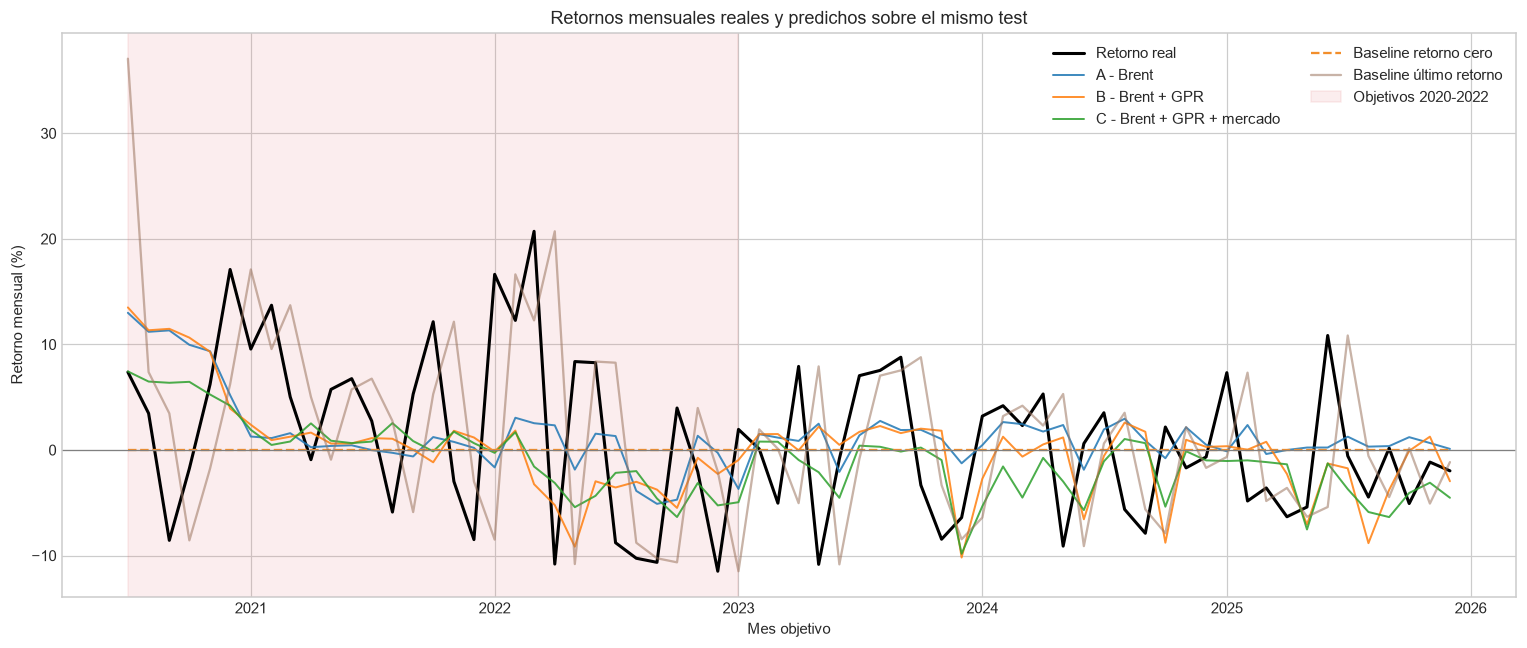

In [6]:
best_scenario = global_selection["escenario"]
best_model_name = global_selection["modelo"]
best_return_prediction = same_algorithm_test_predictions[best_scenario]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(test["target_month"], y_test, color="black", linewidth=2, label="Retorno real")
for scenario, prediction in same_algorithm_test_predictions.items():
    ax.plot(test["target_month"], prediction, linewidth=1.3, alpha=0.85, label=scenario)
ax.plot(test["target_month"], baseline_test_predictions["Baseline - retorno cero"],
        color="#f28e2b", linestyle="--", label="Baseline retorno cero")
ax.plot(test["target_month"], baseline_test_predictions["Baseline - último retorno"],
        color="#9c755f", alpha=0.55, label="Baseline último retorno")
ax.axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2022-12-31"),
           color="#e15759", alpha=0.10, label="Objetivos 2020-2022")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    title="Retornos mensuales reales y predichos sobre el mismo test",
    xlabel="Mes objetivo", ylabel="Retorno mensual (%)",
)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 5. Comparación con el problema de nivel

Para contextualizar la diferencia entre problemas se reconstruye Ridge A, configuración seleccionada en el notebook 03 para predecir el nivel. El gráfico y la tabla se calculan sobre las mismas 66 observaciones. **MAE y RMSE de precio (USD/barril) no se comparan numéricamente con los de retorno (puntos porcentuales)**; solo se contrastan la dificultad relativa, el desempeño frente a sus propios baselines y el R².

Advertencia: MAE/RMSE no son comparables entre filas con unidades diferentes.


,problema,unidad_MAE_RMSE,modelo,escenario,MAE,RMSE,R2
0,Nivel,USD/barril,Ridge,A - Brent,5.014,6.238,0.864
1,Nivel,USD/barril,Persistencia,Baseline,4.942,6.243,0.863
2,Retorno,puntos porcentuales,Baseline - retorno cero,Baseline,6.277,7.608,-0.016
3,Retorno,puntos porcentuales,Random Forest,C - Brent + GPR + mercado,6.580,7.828,-0.075


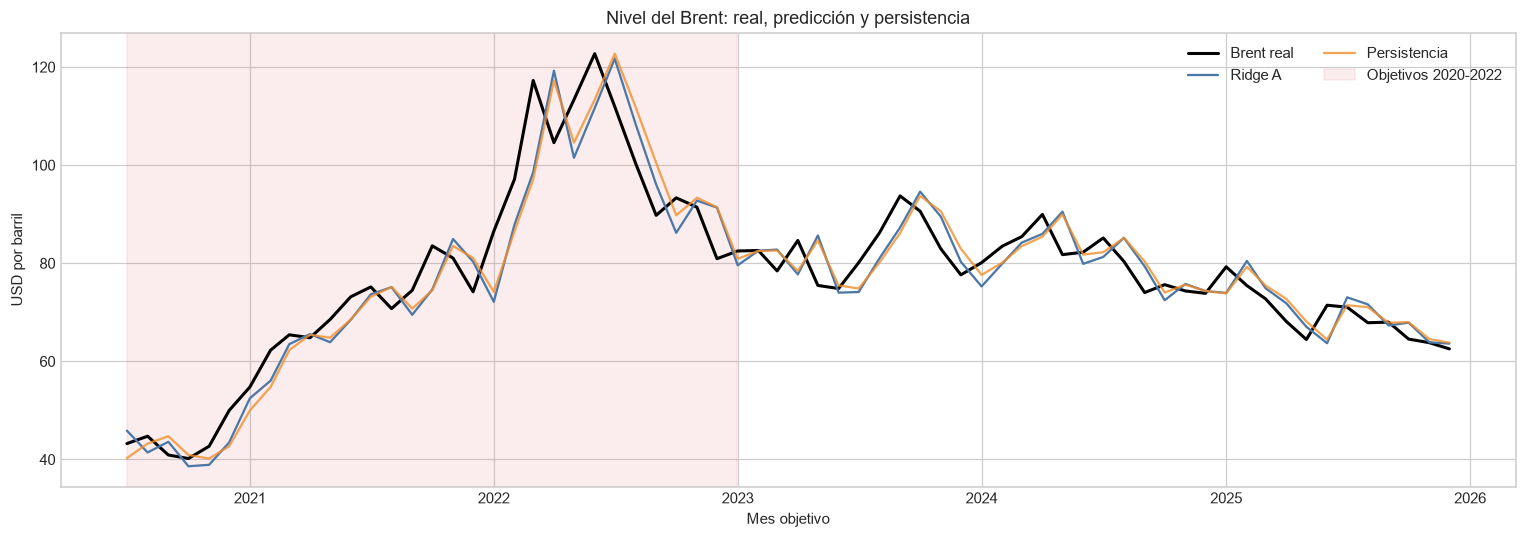

In [7]:
level_model = clone(regression_models["Ridge"]).fit(train[features_a], train["brent_price_next_month"])
level_prediction = level_model.predict(test[features_a])
level_persistence = test["brent_price"].to_numpy()
level_actual = test["brent_price_next_month"].to_numpy()

level_results = pd.DataFrame([
    {"problema": "Nivel", "unidad_MAE_RMSE": "USD/barril", "modelo": "Ridge", "escenario": "A - Brent",
     **metric_row(level_actual, level_prediction)},
    {"problema": "Nivel", "unidad_MAE_RMSE": "USD/barril", "modelo": "Persistencia", "escenario": "Baseline",
     **metric_row(level_actual, level_persistence)},
])
return_results_for_comparison = test_results.loc[
    (test_results["escenario"] == best_scenario)
    | (test_results["modelo_seleccionado_por_CV"] == "Baseline - retorno cero")
].copy()
return_results_for_comparison = return_results_for_comparison.rename(
    columns={"modelo_seleccionado_por_CV": "modelo", "MAE_test": "MAE", "RMSE_test": "RMSE", "R2_test": "R2"}
)
return_results_for_comparison["problema"] = "Retorno"
return_results_for_comparison["unidad_MAE_RMSE"] = "puntos porcentuales"

problem_comparison = pd.concat([
    level_results,
    return_results_for_comparison[["problema", "unidad_MAE_RMSE", "modelo", "escenario", "MAE", "RMSE", "R2"]],
], ignore_index=True)
display(problem_comparison.round(3))
print("Advertencia: MAE/RMSE no son comparables entre filas con unidades diferentes.")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test["target_month"], level_actual, color="black", linewidth=2, label="Brent real")
ax.plot(test["target_month"], level_prediction, color="#4c78a8", label="Ridge A")
ax.plot(test["target_month"], level_persistence, color="#f28e2b", alpha=0.8, label="Persistencia")
ax.axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2022-12-31"),
           color="#e15759", alpha=0.10, label="Objetivos 2020-2022")
ax.set(title="Nivel del Brent: real, predicción y persistencia", xlabel="Mes objetivo", ylabel="USD por barril")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 6. Sensibilidad del test al período 2020–2022

El test comienza en el origen junio de 2020, por lo que sus objetivos empiezan en julio de 2020: no cubre la fase inicial de la caída de la pandemia. La ventana marcada sí incluye la recuperación posterior y 2022, cuando la invasión rusa de Ucrania y las perturbaciones energéticas coincidieron con movimientos abruptos. La comparación es descriptiva: no identifica causalidad ni atribuye todos los errores a esos acontecimientos.

In [8]:
error_analysis = pd.DataFrame({
    "mes_objetivo": test["target_month"].to_numpy(),
    "retorno_real_pct": y_test.to_numpy(),
    "predicción_modelo_pct": best_return_prediction,
    "predicción_cero_pct": baseline_test_predictions["Baseline - retorno cero"],
    "predicción_último_retorno_pct": baseline_test_predictions["Baseline - último retorno"],
    "precio_real_usd": level_actual,
    "predicción_nivel_usd": level_prediction,
    "persistencia_usd": level_persistence,
})
error_analysis["periodo"] = np.where(
    error_analysis["mes_objetivo"].between("2020-01-01", "2022-12-31"),
    "2020-2022", "Resto del test",
)

period_rows = []
for period_name, group in error_analysis.groupby("periodo", sort=False):
    period_rows.extend([
        {"periodo": period_name, "n": len(group), "problema": "Retorno", "modelo": f"{best_model_name} — {best_scenario}",
         "unidad": "p.p.", **metric_row(group["retorno_real_pct"], group["predicción_modelo_pct"])},
        {"periodo": period_name, "n": len(group), "problema": "Retorno", "modelo": "Baseline retorno cero",
         "unidad": "p.p.", **metric_row(group["retorno_real_pct"], group["predicción_cero_pct"])},
        {"periodo": period_name, "n": len(group), "problema": "Nivel", "modelo": "Ridge A",
         "unidad": "USD/barril", **metric_row(group["precio_real_usd"], group["predicción_nivel_usd"])},
        {"periodo": period_name, "n": len(group), "problema": "Nivel", "modelo": "Persistencia",
         "unidad": "USD/barril", **metric_row(group["precio_real_usd"], group["persistencia_usd"])},
    ])
period_comparison = pd.DataFrame(period_rows)
display(period_comparison.round(3))

error_analysis["error_abs_retorno_modelo"] = (
    error_analysis["retorno_real_pct"] - error_analysis["predicción_modelo_pct"]
).abs()
error_analysis["error_abs_nivel_modelo"] = (
    error_analysis["precio_real_usd"] - error_analysis["predicción_nivel_usd"]
).abs()

print("Mayores cambios porcentuales observados en el test:")
display(
    error_analysis.assign(magnitud_retorno=lambda x: x["retorno_real_pct"].abs())
    .nlargest(8, "magnitud_retorno")[[
        "mes_objetivo", "periodo", "retorno_real_pct", "predicción_modelo_pct",
        "error_abs_retorno_modelo", "error_abs_nivel_modelo",
    ]].round(3)
)

Mayores cambios porcentuales observados en el test:


,periodo,n,problema,modelo,unidad,MAE,RMSE,R2
0,2020-2022,30,Retorno,Random Forest — C - Brent + GPR + mercado,p.p.,8.099,9.557,-0.102
1,2020-2022,30,Retorno,Baseline retorno cero,p.p.,8.267,9.515,-0.092
2,2020-2022,30,Nivel,Ridge A,USD/barril,6.456,7.820,0.890
3,2020-2022,30,Nivel,Persistencia,USD/barril,6.486,7.890,0.888
4,Resto del test,36,Retorno,Random Forest — C - Brent + GPR + mercado,p.p.,5.314,6.019,-0.193
5,Resto del test,36,Retorno,Baseline retorno cero,p.p.,4.618,5.538,-0.010
6,Resto del test,36,Nivel,Ridge A,USD/barril,3.813,4.513,0.666
7,Resto del test,36,Nivel,Persistencia,USD/barril,3.655,4.426,0.679


,mes_objetivo,periodo,retorno_real_pct,predicción_modelo_pct,error_abs_retorno_modelo,error_abs_nivel_modelo
20,2022-03-01,2020-2022,20.715,-1.569,22.284,18.699
5,2020-12-01,2020-2022,17.100,4.201,12.899,6.508
18,2022-01-01,2020-2022,16.637,-0.272,16.910,14.375
7,2021-02-01,2020-2022,13.712,0.478,13.234,6.223
19,2022-02-01,2020-2022,12.276,1.687,10.589,9.252
15,2021-10-01,2020-2022,12.149,-0.129,12.279,8.888
29,2022-12-01,2020-2022,-11.485,-5.249,6.236,10.422
59,2025-06-01,Resto del test,10.846,-1.266,12.112,7.740


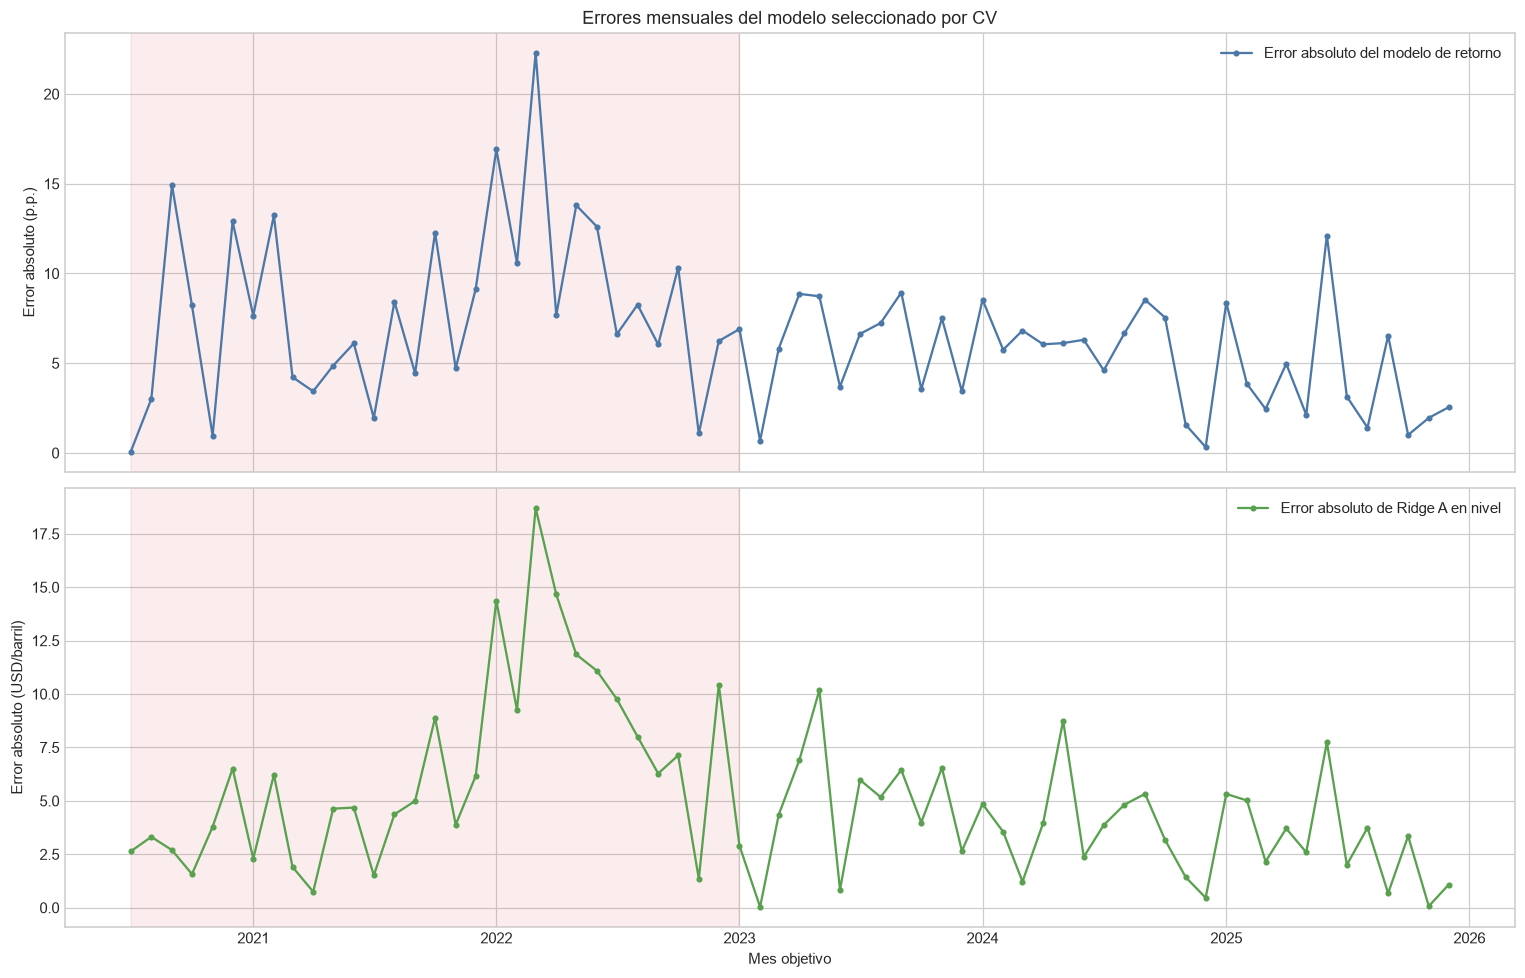

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(error_analysis["mes_objetivo"], error_analysis["error_abs_retorno_modelo"],
             color="#4c78a8", marker="o", markersize=3, label="Error absoluto del modelo de retorno")
axes[0].axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2022-12-31"), color="#e15759", alpha=0.10)
axes[0].set(title="Errores mensuales del modelo seleccionado por CV", ylabel="Error absoluto (p.p.)")
axes[0].legend()

axes[1].plot(error_analysis["mes_objetivo"], error_analysis["error_abs_nivel_modelo"],
             color="#59a14f", marker="o", markersize=3, label="Error absoluto de Ridge A en nivel")
axes[1].axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2022-12-31"), color="#e15759", alpha=0.10)
axes[1].set(xlabel="Mes objetivo", ylabel="Error absoluto (USD/barril)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Conclusiones reproducibles

La siguiente celda deriva las afirmaciones de las tablas calculadas, sin valores escritos a mano. La comparación central es incremental: B contra A para GPR y C contra B para mercado, además de cada resultado frente a los baselines. Diferencias pequeñas o que cambian entre CV y test no se interpretan como evidencia robusta.

In [10]:
test_index = test_results.set_index("escenario")
same_algorithm_cv_index = same_algorithm_cv.set_index("escenario")
same_algorithm_test_index = same_algorithm_test.set_index("escenario")
zero_cv = baseline_cv_summary.set_index("modelo").loc["Baseline - retorno cero"]
zero_test = test_results.loc[
    test_results["modelo_seleccionado_por_CV"] == "Baseline - retorno cero"
].iloc[0]
event_model = period_comparison.query("periodo == '2020-2022' and problema == 'Retorno' and modelo != 'Baseline retorno cero'").iloc[0]
rest_model = period_comparison.query("periodo == 'Resto del test' and problema == 'Retorno' and modelo != 'Baseline retorno cero'").iloc[0]

print("CONCLUSIONES")
print(
    f"1. Mejor configuración de retornos por CV: {best_model_name} en {best_scenario}; "
    f"RMSE CV {global_selection['RMSE_CV']:.3f} p.p. frente a {zero_cv['RMSE_CV']:.3f} del retorno cero."
)
print(
    f"2. En test, esa configuración obtuvo MAE {test_index.loc[best_scenario, 'MAE_test']:.3f}, "
    f"RMSE {test_index.loc[best_scenario, 'RMSE_test']:.3f} y R² {test_index.loc[best_scenario, 'R2_test']:.3f}; "
    f"el retorno cero obtuvo RMSE {zero_test['RMSE_test']:.3f}."
)
print(
    f"3. Con {comparison_model} fijo, efecto incremental en CV: B−A = "
    f"{same_algorithm_cv_index.loc['B - Brent + GPR', 'RMSE_CV'] - same_algorithm_cv_index.loc['A - Brent', 'RMSE_CV']:+.3f} p.p.; "
    f"C−B = {same_algorithm_cv_index.loc['C - Brent + GPR + mercado', 'RMSE_CV'] - same_algorithm_cv_index.loc['B - Brent + GPR', 'RMSE_CV']:+.3f} p.p. "
    "(negativo implica menor error)."
)
print(
    f"4. La ventana 2020–2022 contiene {int(event_model['n'])} objetivos y el resto {int(rest_model['n'])}; "
    f"RMSE del modelo: {event_model['RMSE']:.3f} frente a {rest_model['RMSE']:.3f} p.p."
)
print(
    f"5. En nivel, Ridge A alcanzó RMSE {level_results.iloc[0]['RMSE']:.3f} USD/barril y "
    f"R² {level_results.iloc[0]['R2']:.3f}; la persistencia obtuvo RMSE {level_results.iloc[1]['RMSE']:.3f}. "
    "La aparente facilidad del nivel refleja su persistencia y no es trasladable al retorno."
)

print(
    f"6. Con {comparison_model} fijo, efecto incremental en test histórico: B−A = "
    f"{same_algorithm_test_index.loc['B - Brent + GPR', 'RMSE_test'] - same_algorithm_test_index.loc['A - Brent', 'RMSE_test']:+.3f} p.p.; "
    f"C−B = {same_algorithm_test_index.loc['C - Brent + GPR + mercado', 'RMSE_test'] - same_algorithm_test_index.loc['B - Brent + GPR', 'RMSE_test']:+.3f} p.p."
)
print(
    "7. Aunque las variables adicionales reducen levemente el RMSE del bosque en CV, "
    "todos los escenarios quedan detrás del retorno cero; el test tampoco muestra una mejora incremental estable. "
    "No hay evidencia robusta de utilidad predictiva adicional de GPR o mercado."
)

summary = {
    "target": "brent_return_next_month_pct",
    "train_origin_period": [train["month"].min().strftime("%Y-%m"), train["month"].max().strftime("%Y-%m")],
    "test_origin_period": [test["month"].min().strftime("%Y-%m"), test["month"].max().strftime("%Y-%m")],
    "test_target_period": [test["target_month"].min().strftime("%Y-%m"), test["target_month"].max().strftime("%Y-%m")],
    "selected_return_scenario_by_cv": best_scenario,
    "selected_return_model_by_cv": best_model_name,
    "return_test_results": test_results.to_dict(orient="records"),
    "same_algorithm_test": same_algorithm_test.to_dict(orient="records"),
    "period_comparison": period_comparison.to_dict(orient="records"),
}
print("\nRESULTADOS_RESUMEN")
print(json.dumps(summary, ensure_ascii=False, indent=2, default=str))

CONCLUSIONES
1. Mejor configuración de retornos por CV: Random Forest en C - Brent + GPR + mercado; RMSE CV 11.805 p.p. frente a 10.119 del retorno cero.
2. En test, esa configuración obtuvo MAE 6.580, RMSE 7.828 y R² -0.075; el retorno cero obtuvo RMSE 7.608.
3. Con Random Forest fijo, efecto incremental en CV: B−A = -0.351 p.p.; C−B = -0.121 p.p. (negativo implica menor error).
4. La ventana 2020–2022 contiene 30 objetivos y el resto 36; RMSE del modelo: 9.557 frente a 6.019 p.p.
5. En nivel, Ridge A alcanzó RMSE 6.238 USD/barril y R² 0.864; la persistencia obtuvo RMSE 6.243. La aparente facilidad del nivel refleja su persistencia y no es trasladable al retorno.
6. Con Random Forest fijo, efecto incremental en test histórico: B−A = +0.525 p.p.; C−B = -0.566 p.p.
7. Aunque las variables adicionales reducen levemente el RMSE del bosque en CV, todos los escenarios quedan detrás del retorno cero; el test tampoco muestra una mejora incremental estable. No hay evidencia robusta de utilidad

## Limitaciones

- El test fue observado durante el desarrollo del proyecto y se presenta como evaluación histórica, no como holdout completamente intacto.
- El tramo extraordinario contiene pocos meses y el test no incluye el inicio de 2020; sus métricas son descriptivas y sensibles a observaciones extremas.
- GPR y STEO se retrasan un mes como aproximación conservadora, pero las fechas de publicación históricas no se reconstruyen. STEO contiene historia revisada.
- La muestra mensual es pequeña para modelos flexibles. Un resultado negativo frente a baselines es informativo y no debe ocultarse mediante exclusión de períodos.
- SHAP y LIME permanecen como complementos del experimento de nivel; no se repiten aquí porque la pregunta principal es la comparación homogénea de escenarios y baselines.